# Global Procurement & Supplier Performance Analytics

### Enterprise Analytics Notebook

**Business Domain:** Procurement & Strategic Sourcing
**Project Level:** Senior Business Intelligence
**Primary Tools:** Python, SQL (SQLite/SQL Server), Power BI, Scikit-learn

---

## Business Objective

Procurement organizations must balance cost optimization, supplier performance, operational efficiency, and supply continuity. This project develops an end-to-end analytics solution that transforms procurement transactions into actionable insights for procurement managers and executive leadership.

---

## Notebook Objectives

This notebook demonstrates the complete analytics workflow by:

* Loading the procurement data warehouse tables
* Validating the core procurement KPIs using SQL
* Performing exploratory business analysis
* Building supplier risk scores
* Forecasting procurement spend
* Segmenting suppliers using machine learning
* Generating business insights and recommendations

---

## Business Questions

This analysis answers questions such as:

* Which suppliers present the highest operational risk?
* Where are the largest procurement savings opportunities?
* How effectively are suppliers meeting delivery commitments?
* Which supplier segments require different sourcing strategies?
* What procurement spend is expected over the coming months?

---

## Project Workflow

1. Load and validate warehouse data
2. Verify procurement KPIs
3. Perform exploratory analysis
4. Build supplier risk model
5. Forecast procurement spend
6. Segment suppliers
7. Summarize business insights

---

## Expected Deliverables

* Executive KPI dashboard
* Supplier performance analysis
* Risk scoring model
* Spend forecast
* Supplier segmentation
* Strategic procurement recommendations

> **Note:** This project uses a simulated transactional dataset generated from public enterprise procurement models (AdventureWorks Purchasing and SAP MM concepts) to demonstrate a production-style analytics workflow.


In [12]:
# ============================================================
# 01. Environment Setup
# ============================================================

from pathlib import Path
import warnings
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler, StandardScaler


# ------------------------------------------------------------
# Google Drive (Colab)
# ------------------------------------------------------------
try:
    from google.colab import drive

    drive.mount("/content/drive")

    PROJECT_ROOT = Path(
        "/content/drive/MyDrive/global-procurement-analytics"
    )

except ImportError:
    # Local Jupyter / VS Code
    PROJECT_ROOT = Path.cwd()


# ------------------------------------------------------------
# Project Directories
# ------------------------------------------------------------
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"

assert RAW_DATA_DIR.exists(), f"Raw data folder not found: {RAW_DATA_DIR}"
assert PROCESSED_DATA_DIR.exists(), f"Processed data folder not found: {PROCESSED_DATA_DIR}"


# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------
RANDOM_STATE = 42


# ------------------------------------------------------------
# Pandas Display Options
# ------------------------------------------------------------
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

warnings.filterwarnings("ignore", category=FutureWarning)


# ------------------------------------------------------------
# Visualization Theme
# ------------------------------------------------------------
COLOR_PALETTE = [
    "#2A6F6F",
    "#5B8DEF",
    "#F0A93A",
    "#9C6FE0",
    "#E0645A",
    "#4FB6A8",
    "#7C9CBF",
]

sns.set_theme(
    style="whitegrid",
    rc={
        "axes.facecolor": "white",
        "figure.facecolor": "white",
        "axes.edgecolor": "#333333",
        "grid.color": "#E6E6E6",
    },
)

sns.set_palette(COLOR_PALETTE)


# ------------------------------------------------------------
# Environment Summary
# ------------------------------------------------------------
print("=" * 60)
print("Global Procurement Analytics")
print("=" * 60)
print(f"Project Root      : {PROJECT_ROOT}")
print(f"Raw Data          : {RAW_DATA_DIR}")
print(f"Processed Data    : {PROCESSED_DATA_DIR}")
print(f"Random State      : {RANDOM_STATE}")
print("=" * 60)
print("Environment initialized successfully.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Global Procurement Analytics
Project Root      : /content/drive/MyDrive/global-procurement-analytics
Raw Data          : /content/drive/MyDrive/global-procurement-analytics/data/raw
Processed Data    : /content/drive/MyDrive/global-procurement-analytics/data/processed
Random State      : 42
Environment initialized successfully.


## 1. Load Enterprise Data Warehouse

Load the procurement fact and dimension tables required for analysis.

In [13]:
# ============================================================
# 02. Load Procurement Data Warehouse
# ============================================================

# ------------------------------------------------------------
# Source File Map
# ------------------------------------------------------------
TABLE_FILES = {
    "DimDate": "dim_date.csv",
    "DimRegion": "dim_region.csv",
    "DimPlant": "dim_plant.csv",
    "DimCategory": "dim_category.csv",
    "DimBuyer": "dim_buyer.csv",
    "DimSupplier": "dim_supplier.csv",
    "FactContracts": "fact_contracts.csv",
    "FactPurchaseOrders": "fact_purchase_orders.csv",
    "FactSupplierDeliveries": "fact_supplier_deliveries.csv",
    "FactProcurementSpend": "fact_procurement_spend.csv",
}


# ------------------------------------------------------------
# Validate Source Files
# ------------------------------------------------------------
missing_files = [
    file_name
    for file_name in TABLE_FILES.values()
    if not (RAW_DATA_DIR / file_name).exists()
]

if missing_files:
    raise FileNotFoundError(
        "Missing required source files:\n"
        + "\n".join(f"- {file_name}" for file_name in missing_files)
    )


# ------------------------------------------------------------
# Load Dimension and Fact Tables
# ------------------------------------------------------------
warehouse_tables = {
    table_name: pd.read_csv(RAW_DATA_DIR / file_name)
    for table_name, file_name in TABLE_FILES.items()
}

dim_date = warehouse_tables["DimDate"]
dim_region = warehouse_tables["DimRegion"]
dim_plant = warehouse_tables["DimPlant"]
dim_category = warehouse_tables["DimCategory"]
dim_buyer = warehouse_tables["DimBuyer"]
dim_supplier = warehouse_tables["DimSupplier"]

fact_contracts = warehouse_tables["FactContracts"]
fact_purchase_orders = warehouse_tables["FactPurchaseOrders"]
fact_supplier_deliveries = warehouse_tables["FactSupplierDeliveries"]
fact_procurement_spend = warehouse_tables["FactProcurementSpend"]


# ------------------------------------------------------------
# Data Warehouse Summary
# ------------------------------------------------------------
warehouse_summary = (
    pd.DataFrame(
        [
            {
                "Table": table_name,
                "Table Type": (
                    "Dimension"
                    if table_name.startswith("Dim")
                    else "Fact"
                ),
                "Rows": dataframe.shape[0],
                "Columns": dataframe.shape[1],
                "Memory (MB)": dataframe.memory_usage(
                    deep=True
                ).sum() / 1_048_576,
            }
            for table_name, dataframe in warehouse_tables.items()
        ]
    )
    .sort_values(["Table Type", "Table"])
    .reset_index(drop=True)
)

print(
    f"Loaded {len(warehouse_tables)} warehouse tables "
    f"from {RAW_DATA_DIR}"
)

display(warehouse_summary)



Loaded 10 warehouse tables from /content/drive/MyDrive/global-procurement-analytics/data/raw


,Table,Table Type,Rows,Columns,Memory (MB)
0,DimBuyer,Dimension,24,5,0.01
1,DimCategory,Dimension,16,5,0.00
2,DimDate,Dimension,1277,14,0.42
3,DimPlant,Dimension,15,4,0.00
4,DimRegion,Dimension,10,4,0.00
5,DimSupplier,Dimension,60,10,0.02
6,FactContracts,Fact,83,9,0.02
7,FactProcurementSpend,Fact,42000,9,2.60
8,FactPurchaseOrders,Fact,42000,13,5.77
9,FactSupplierDeliveries,Fact,42000,12,3.00


## 2.1 Preview Supplier Dimension

Inspect the supplier master data to verify that the supplier dimension has been loaded correctly and contains the expected business attributes before downstream analysis.

In [14]:
# ============================================================
# Supplier Dimension Overview
# ============================================================

print("=" * 60)
print("Supplier Dimension")
print("=" * 60)

print(f"Rows       : {dim_supplier.shape[0]:,}")
print(f"Columns    : {dim_supplier.shape[1]}")
print(f"Memory     : {dim_supplier.memory_usage(deep=True).sum()/1024:.1f} KB")

display(dim_supplier.head())

print("\nColumn Information")
display(
    pd.DataFrame({
        "Column": dim_supplier.columns,
        "Data Type": dim_supplier.dtypes.astype(str).values
    })
)


Supplier Dimension
Rows       : 60
Columns    : 10
Memory     : 22.6 KB


,SupplierKey,SupplierName,SupplierCode,SupplierTier,RegionKey,Country,OnboardDate,BaseReliabilityScore,BaseQualityScore,SupplierStatus
0,1,Compass Inc.,SUP-0001,Preferred,9,Mexico,2023-05-27,0.99,0.96,Active
1,2,Meridian Supply Co.,SUP-0002,Preferred,9,Mexico,2018-09-16,0.69,0.97,Under Review
2,3,Reliable Partners,SUP-0003,Approved,2,Canada,2020-03-14,0.78,0.93,Under Review
3,4,Falcon Corp,SUP-0004,Preferred,7,India,2022-07-18,0.86,0.93,Active
4,5,Anchor Inc.,SUP-0005,Transactional,3,Germany,2023-12-26,0.82,0.97,Active



Column Information


,Column,Data Type
0,SupplierKey,int64
1,SupplierName,object
2,SupplierCode,object
3,SupplierTier,object
4,RegionKey,int64
5,Country,object
6,OnboardDate,object
7,BaseReliabilityScore,float64
8,BaseQualityScore,float64
9,SupplierStatus,object


## 2. Validate KPI Logic in SQLite

Load the procurement warehouse tables into an in-memory SQLite database and validate the core KPI calculations against the SQL logic in `sql/02_views_kpis.sql`.

In [15]:
# ============================================================
# Build In-Memory SQLite Data Warehouse
# ============================================================

# Create SQLite in-memory database
conn = sqlite3.connect(":memory:")

# ------------------------------------------------------------
# Load Warehouse Tables
# ------------------------------------------------------------
for table_name, dataframe in warehouse_tables.items():
    dataframe.to_sql(
        table_name,
        conn,
        if_exists="replace",
        index=False
    )

# ------------------------------------------------------------
# Create Performance Indexes
# ------------------------------------------------------------
conn.execute("""
    CREATE INDEX idx_po_supplier
    ON FactPurchaseOrders (SupplierKey)
""")

conn.execute("""
    CREATE INDEX idx_spend_supplier
    ON FactProcurementSpend (SupplierKey)
""")

conn.execute("""
    CREATE INDEX idx_delivery_supplier
    ON FactSupplierDeliveries (SupplierKey)
""")

conn.commit()

# ------------------------------------------------------------
# Load Validation
# ------------------------------------------------------------
warehouse_status = pd.DataFrame({
    "Table": warehouse_tables.keys(),
    "Rows": [len(df) for df in warehouse_tables.values()]
})

print(f"SQLite warehouse initialized successfully.")
print(f"Database Type : In-Memory")
print(f"Tables Loaded : {len(warehouse_tables)}")
print(f"Indexes Created : 3")

display(warehouse_status)

SQLite warehouse initialized successfully.
Database Type : In-Memory
Tables Loaded : 10
Indexes Created : 3


,Table,Rows
0,DimDate,1277
1,DimRegion,10
2,DimPlant,15
3,DimCategory,16
4,DimBuyer,24
5,DimSupplier,60
6,FactContracts,83
7,FactPurchaseOrders,42000
8,FactSupplierDeliveries,42000
9,FactProcurementSpend,42000


## 3. KPI Validation

Validate the enterprise procurement KPIs using SQL queries executed against the in-memory warehouse. This ensures that all downstream analysis and Power BI reports are based on a consistent set of business metrics.

### KPI 1 — Spend Under Management & Procurement Savings

Validate annual procurement spend, managed spend, and realized savings. These metrics measure procurement effectiveness, contract coverage, and cost optimization across the organization.

In [16]:
# ============================================================
# KPI 1: Spend Under Management & Procurement Savings
# ============================================================

query = """
SELECT
    d.Year,

    ROUND(SUM(s.ActualSpend), 0) AS TotalSpend,

    ROUND(
        SUM(
            CASE
                WHEN sup.SupplierStatus = 'Active'
                THEN s.ActualSpend
                ELSE 0
            END
        ),
        0
    ) AS ManagedSpend,

    ROUND(
        100.0 *
        SUM(
            CASE
                WHEN sup.SupplierStatus = 'Active'
                THEN s.ActualSpend
                ELSE 0
            END
        ) / SUM(s.ActualSpend),
        1
    ) AS SUM_Pct,

    ROUND(SUM(s.BaselineSpend), 0) AS BaselineSpend,

    ROUND(
        SUM(s.BaselineSpend) - SUM(s.ActualSpend),
        0
    ) AS RealizedSavings,

    ROUND(
        100.0 *
        (SUM(s.BaselineSpend) - SUM(s.ActualSpend))
        / SUM(s.BaselineSpend),
        2
    ) AS SavingsPct

FROM FactProcurementSpend s
JOIN DimDate d
    ON d.DateKey = s.OrderDateKey
JOIN DimSupplier sup
    ON sup.SupplierKey = s.SupplierKey

GROUP BY d.Year
ORDER BY d.Year;
"""

kpi_spend_summary = pd.read_sql_query(query, conn)

display(kpi_spend_summary)

,Year,TotalSpend,ManagedSpend,SUM_Pct,BaselineSpend,RealizedSavings,SavingsPct
0,2022,"663,215,890.00","425,135,039.00",64.10,"684,859,587.00","21,643,696.00",3.16
1,2023,"666,865,508.00","434,284,375.00",65.10,"688,770,862.00","21,905,353.00",3.18
2,2024,"670,547,422.00","435,917,110.00",65.00,"692,308,382.00","21,760,960.00",3.14
3,2025,"314,132,940.00","203,492,109.00",64.80,"323,892,534.00","9,759,594.00",3.01


### KPI 3 — Supplier On-Time-In-Full Performance

Measure the percentage of supplier deliveries received both on or before the committed date and in the full ordered quantity. OTIF is a key indicator of supplier reliability, production continuity, and service-level performance.

In [17]:
# ============================================================
# KPI 3: Supplier On-Time-In-Full (OTIF)
# ============================================================

query = """
SELECT
    sup.SupplierName,
    sup.SupplierTier,

    COUNT(*) AS Deliveries,

    ROUND(
        100.0 * SUM(del.OTIFFlag) / COUNT(*),
        1
    ) AS OTIF_Pct,

    ROUND(
        100.0 * SUM(del.OnTimeFlag) / COUNT(*),
        1
    ) AS OnTime_Pct,

    ROUND(
        100.0 * SUM(del.InFullFlag) / COUNT(*),
        1
    ) AS InFull_Pct

FROM FactSupplierDeliveries AS del
JOIN DimSupplier AS sup
    ON sup.SupplierKey = del.SupplierKey

GROUP BY
    sup.SupplierKey,
    sup.SupplierName,
    sup.SupplierTier

ORDER BY Deliveries DESC
LIMIT 10;
"""

kpi_otif = pd.read_sql_query(query, conn)

display(kpi_otif)

# ------------------------------------------------------------
# Enterprise OTIF Summary
# ------------------------------------------------------------

enterprise_otif = pd.read_sql_query(
    """
    SELECT
        ROUND(AVG(OTIFFlag) * 100, 1) AS Enterprise_OTIF
    FROM FactSupplierDeliveries;
    """,
    conn,
)

print(f"\nEnterprise OTIF: {enterprise_otif.loc[0, 'Enterprise_OTIF']:.1f}%")

,SupplierName,SupplierTier,Deliveries,OTIF_Pct,OnTime_Pct,InFull_Pct
0,Momentum Materials,Transactional,772,76.00,77.80,97.50
1,Meridian Ltd.,Approved,745,89.00,91.50,97.00
2,Highland Manufacturing,Strategic,740,77.40,79.10,98.10
3,Fusion Supply Co.,Transactional,738,97.60,99.30,98.20
4,Highland Corp,Preferred,735,96.50,99.20,97.30
5,Everest Group,Approved,733,80.50,82.00,98.00
6,Reliable Partners,Approved,732,74.20,76.40,97.10
7,Novus Materials,Approved,729,75.70,78.20,97.10
8,Beacon Supply Co.,Transactional,729,80.40,83.80,95.70
9,Everest Industries,Transactional,727,63.50,66.70,95.20



Enterprise OTIF: 80.7%


### KPI 4 — Procurement Lead Time & Purchase Order Cycle Time

Measure the average supplier lead time and purchase order cycle time to evaluate procurement efficiency and identify opportunities to reduce sourcing delays.

In [18]:
# ============================================================
# KPI 4: Procurement Lead Time & Purchase Order Cycle Time
# ============================================================

query = """
SELECT
    ROUND(
        AVG(
            julianday(
                substr(ActualDeliveryDateKey,1,4) || '-' ||
                substr(ActualDeliveryDateKey,5,2) || '-' ||
                substr(ActualDeliveryDateKey,7,2)
            )
            -
            julianday(
                substr(OrderDateKey,1,4) || '-' ||
                substr(OrderDateKey,5,2) || '-' ||
                substr(OrderDateKey,7,2)
            )
        ),
        1
    ) AS AvgLeadTimeDays,

    ROUND(
        AVG(
            julianday(
                substr(PromisedDateKey,1,4) || '-' ||
                substr(PromisedDateKey,5,2) || '-' ||
                substr(PromisedDateKey,7,2)
            )
            -
            julianday(
                substr(OrderDateKey,1,4) || '-' ||
                substr(OrderDateKey,5,2) || '-' ||
                substr(OrderDateKey,7,2)
            )
        ),
        1
    ) AS AvgCycleTimeDays

FROM FactSupplierDeliveries;
"""

kpi_lead_cycle = pd.read_sql_query(query, conn)

display(kpi_lead_cycle)

,AvgLeadTimeDays,AvgCycleTimeDays
0,27.70,26.20


### KPI 5 — Supplier Defect Rate (Quality Risk Bands)

Assess supplier quality performance by measuring defect rates and classifying suppliers into quality risk bands. This analysis helps prioritize supplier development, reduce quality-related costs, and mitigate supply chain risk.

In [19]:
# ============================================================
# KPI 5: Supplier Defect Rate and Quality Risk Bands
# ============================================================

query = """
WITH supplier_quality AS (
    SELECT
        sup.SupplierKey,
        sup.SupplierName,
        SUM(del.QtyReceived) AS UnitsReceived,
        SUM(del.DefectUnits) AS DefectUnits,
        1.0 * SUM(del.DefectUnits) / NULLIF(SUM(del.QtyReceived), 0) AS DefectRate
    FROM FactSupplierDeliveries AS del
    JOIN DimSupplier AS sup
        ON sup.SupplierKey = del.SupplierKey
    GROUP BY
        sup.SupplierKey,
        sup.SupplierName
)

SELECT
    CASE
        WHEN DefectRate >= 0.05 THEN 'High Risk'
        WHEN DefectRate >= 0.02 THEN 'Moderate Risk'
        ELSE 'Low Risk'
    END AS RiskBand,

    COUNT(*) AS SupplierCount,

    ROUND(
        100.0 * AVG(DefectRate),
        2
    ) AS AvgDefectRatePct

FROM supplier_quality

GROUP BY RiskBand

ORDER BY AvgDefectRatePct DESC;
"""

kpi_defect_risk = pd.read_sql_query(query, conn)

display(kpi_defect_risk)

,RiskBand,SupplierCount,AvgDefectRatePct
0,Moderate Risk,1,2.46
1,Low Risk,59,0.84


### KPI 6 — Contract Compliance & Maverick Spend

Measure contract compliance and identify off-contract (maverick) spend to evaluate procurement governance, purchasing discipline, and opportunities for cost savings through strategic sourcing.

In [20]:
# ============================================================
# KPI 6: Contract Compliance and Maverick Spend
# ============================================================

query = """
SELECT
    cat.CategoryGroup,

    ROUND(
        SUM(f.ActualSpend),
        0
    ) AS TotalSpend,

    ROUND(
        100.0 *
        SUM(
            CASE
                WHEN f.IsUnderContract = 1
                THEN f.ActualSpend
                ELSE 0
            END
        ) / NULLIF(SUM(f.ActualSpend), 0),
        1
    ) AS ContractCompliancePct,

    ROUND(
        100.0 *
        SUM(
            CASE
                WHEN f.IsUnderContract = 0
                THEN f.ActualSpend
                ELSE 0
            END
        ) / NULLIF(SUM(f.ActualSpend), 0),
        1
    ) AS MaverickSpendPct

FROM FactProcurementSpend AS f
JOIN DimCategory AS cat
    ON cat.CategoryKey = f.CategoryKey

GROUP BY cat.CategoryGroup

ORDER BY MaverickSpendPct DESC;
"""

kpi_contract_compliance = pd.read_sql_query(query, conn)

display(kpi_contract_compliance)

,CategoryGroup,TotalSpend,ContractCompliancePct,MaverickSpendPct
0,Professional Services,"297,376,097.00",48.90,51.10
1,Packaging,"288,111,535.00",49.30,50.70
2,IT & Telecom,"285,154,331.00",50.10,49.90
3,Logistics,"289,584,224.00",50.20,49.80
4,MRO,"431,430,659.00",50.80,49.20
5,Raw Materials,"580,012,502.00",51.00,49.00
6,Marketing,"143,092,413.00",52.60,47.40


### KPI 7 — Weighted Supplier Scorecard (window functions: RANK, NTILE)### KPI 7 — Weighted Supplier Scorecard & Performance Ranking

Evaluate supplier performance using a weighted scorecard that combines delivery, quality, compliance, and commercial metrics. Ranking and quartile segmentation help identify strategic suppliers, development priorities, and high-risk vendors.

In [21]:
# ============================================================
# KPI 7: Weighted Supplier Scorecard & Performance Ranking
# ============================================================

query = """
WITH otif AS (
    SELECT
        SupplierKey,
        AVG(1.0 * OTIFFlag) AS OTIFRate
    FROM FactSupplierDeliveries
    GROUP BY SupplierKey
),

quality AS (
    SELECT
        SupplierKey,
        1.0 - (
            1.0 * SUM(DefectUnits)
            / NULLIF(SUM(QtyReceived), 0)
        ) AS QualityRate
    FROM FactSupplierDeliveries
    GROUP BY SupplierKey
),

savings AS (
    SELECT
        SupplierKey,
        (
            1.0 * SUM(BaselineSpend) - SUM(ActualSpend)
        ) / NULLIF(SUM(BaselineSpend), 0) AS SavingsRate
    FROM FactProcurementSpend
    GROUP BY SupplierKey
),

compliance AS (
    SELECT
        SupplierKey,
        1.0 *
        SUM(
            CASE
                WHEN IsUnderContract = 1
                THEN ActualSpend
                ELSE 0
            END
        ) / NULLIF(SUM(ActualSpend), 0) AS ComplianceRate
    FROM FactProcurementSpend
    GROUP BY SupplierKey
),

blended AS (
    SELECT
        s.SupplierKey,
        s.SupplierName,
        s.SupplierTier,

        COALESCE(o.OTIFRate, 0) AS OTIFRate,
        COALESCE(q.QualityRate, 0) AS QualityRate,

        MIN(
            1.0,
            MAX(
                0.0,
                COALESCE(sv.SavingsRate, 0) / 0.08
            )
        ) AS CostPerformanceIndex,

        COALESCE(c.ComplianceRate, 0) AS ComplianceRate

    FROM DimSupplier AS s

    LEFT JOIN otif AS o
        ON o.SupplierKey = s.SupplierKey

    LEFT JOIN quality AS q
        ON q.SupplierKey = s.SupplierKey

    LEFT JOIN savings AS sv
        ON sv.SupplierKey = s.SupplierKey

    LEFT JOIN compliance AS c
        ON c.SupplierKey = s.SupplierKey
),

scored AS (
    SELECT
        SupplierKey,
        SupplierName,
        SupplierTier,
        OTIFRate,
        QualityRate,
        CostPerformanceIndex,
        ComplianceRate,

        (
            OTIFRate * 0.35
            + QualityRate * 0.30
            + CostPerformanceIndex * 0.20
            + ComplianceRate * 0.15
        ) AS WeightedScore

    FROM blended
)

SELECT
    SupplierName,
    SupplierTier,

    ROUND(OTIFRate, 3) AS OTIF,
    ROUND(QualityRate, 3) AS Quality,
    ROUND(CostPerformanceIndex, 3) AS CostPerformance,
    ROUND(ComplianceRate, 3) AS Compliance,
    ROUND(WeightedScore, 4) AS WeightedScore,

    RANK() OVER (
        ORDER BY WeightedScore DESC
    ) AS OverallRank,

    NTILE(4) OVER (
        ORDER BY WeightedScore DESC
    ) AS PerformanceQuartile

FROM scored

ORDER BY WeightedScore DESC
LIMIT 10;
"""

kpi_supplier_scorecard = pd.read_sql_query(query, conn)

display(kpi_supplier_scorecard)

,SupplierName,SupplierTier,OTIF,Quality,CostPerformance,Compliance,WeightedScore,OverallRank,PerformanceQuartile
0,Titan Ltd.,Strategic,0.92,0.99,1.00,0.84,0.95,1,1
1,Compass Inc.,Preferred,0.97,1.00,0.91,0.78,0.94,2,1
2,Beacon Group,Strategic,0.89,1.00,0.95,0.82,0.93,3,1
3,Highland Corp,Preferred,0.96,0.99,0.87,0.76,0.92,4,1
4,Pinnacle Partners,Strategic,0.82,1.00,1.00,0.88,0.92,5,1
5,Novus Partners,Preferred,0.95,0.99,0.86,0.76,0.92,6,1
6,Precision Group,Strategic,0.81,0.99,1.00,0.89,0.92,7,1
7,Orbit Partners,Strategic,0.82,0.99,1.00,0.87,0.91,8,1
8,Coastal Corp,Preferred,0.89,0.99,0.87,0.78,0.90,9,1
9,Anchor Partners,Preferred,0.85,0.99,0.89,0.79,0.89,10,1


## 4. Executive Procurement Performance Dashboard

Visualize the validated procurement KPIs through executive dashboards to evaluate spend, supplier performance, procurement efficiency, and compliance.

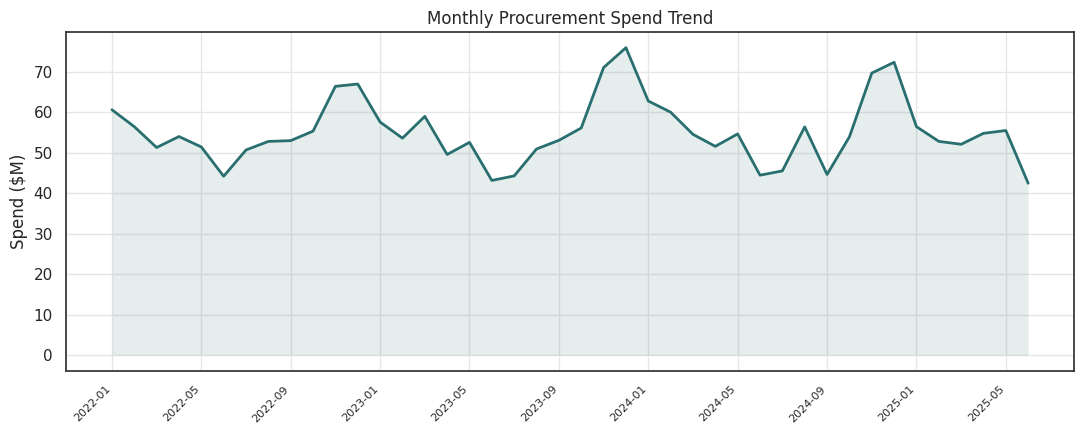

In [22]:
# ============================================================
# Monthly Procurement Spend Trend
# ============================================================

monthly_spend = (
    fact_procurement_spend
    .merge(
        dim_date[["DateKey", "YearMonth"]],
        left_on="OrderDateKey",
        right_on="DateKey",
        how="left"
    )
    .groupby("YearMonth", as_index=False)["ActualSpend"]
    .sum()
    .sort_values("YearMonth")
)

monthly_spend["SpendMillions"] = monthly_spend["ActualSpend"] / 1_000_000

fig, ax = plt.subplots(figsize=(11, 4.5))

ax.plot(
    monthly_spend["YearMonth"],
    monthly_spend["SpendMillions"],
    linewidth=2
)

ax.fill_between(
    monthly_spend["YearMonth"],
    monthly_spend["SpendMillions"],
    alpha=0.12
)

ax.set_title("Monthly Procurement Spend Trend")
ax.set_ylabel("Spend ($M)")
ax.set_xlabel("")

ax.xaxis.set_major_locator(mticker.MultipleLocator(4))
plt.xticks(rotation=45, ha="right", fontsize=8)

plt.tight_layout()
plt.show()

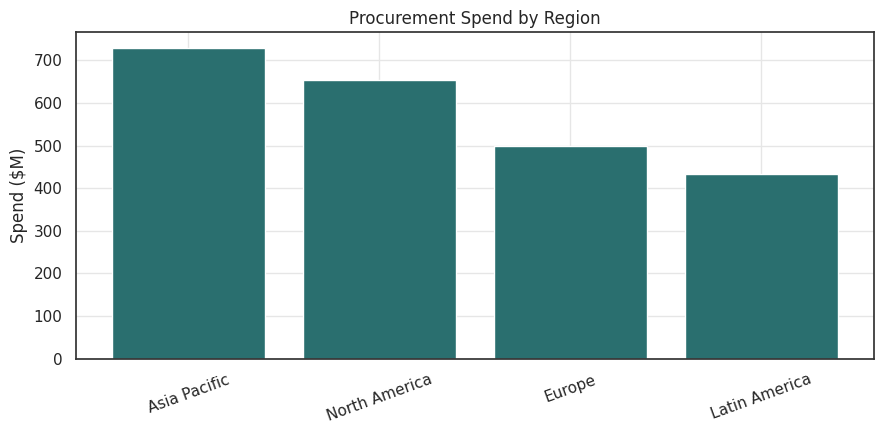

In [23]:
# ============================================================
# Procurement Spend by Region
# ============================================================

regional_spend = (
    fact_procurement_spend
    .merge(
        dim_supplier[["SupplierKey", "RegionKey"]],
        on="SupplierKey",
        how="left"
    )
    .merge(
        dim_region[["RegionKey", "RegionName"]],
        on="RegionKey",
        how="left"
    )
    .groupby("RegionName", as_index=False)["ActualSpend"]
    .sum()
    .sort_values("ActualSpend", ascending=False)
)

regional_spend["SpendMillions"] = (
    regional_spend["ActualSpend"] / 1_000_000
)

fig, ax = plt.subplots(figsize=(9, 4.5))

ax.bar(
    regional_spend["RegionName"],
    regional_spend["SpendMillions"]
)

ax.set_title("Procurement Spend by Region")
ax.set_ylabel("Spend ($M)")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()



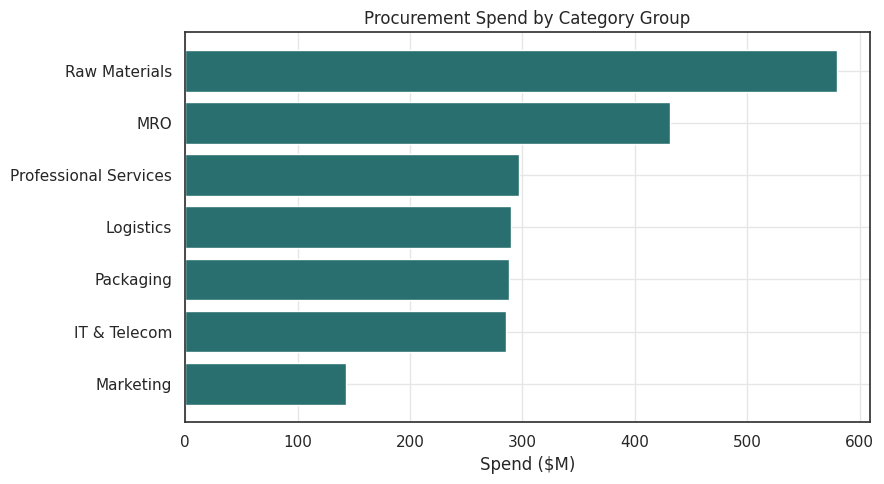

In [24]:
# ============================================================
# Procurement Spend by Category Group
# ============================================================

category_spend = (
    fact_procurement_spend
    .merge(
        dim_category[["CategoryKey", "CategoryGroup"]],
        on="CategoryKey",
        how="left"
    )
    .groupby("CategoryGroup", as_index=False)["ActualSpend"]
    .sum()
    .sort_values("ActualSpend", ascending=True)
)

category_spend["SpendMillions"] = (
    category_spend["ActualSpend"] / 1_000_000
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.barh(
    category_spend["CategoryGroup"],
    category_spend["SpendMillions"]
)

ax.set_title("Procurement Spend by Category Group")
ax.set_xlabel("Spend ($M)")
ax.set_ylabel("")

plt.tight_layout()
plt.show()

## 5. Supplier Risk Scoring

Develop a composite supplier risk score using delivery reliability, quality, compliance, spend concentration, and recent performance trends.

Isolation Forest is used alongside the weighted score to identify suppliers with unusual multivariate risk patterns that may not be visible through individual KPIs alone.

In [25]:
# ============================================================
# Supplier Risk Scoring
# ============================================================

# ------------------------------------------------------------
# 1. Delivery & Quality Performance
# ------------------------------------------------------------

delivery_summary = (
    fact_supplier_deliveries
    .groupby("SupplierKey")
    .agg(
        Deliveries=("POKey", "count"),
        OTIFRate=("OTIFFlag", "mean"),
        TotalDefects=("DefectUnits", "sum"),
        TotalReceived=("QtyReceived", "sum"),
    )
    .reset_index()
)

delivery_summary["DefectRate"] = (
    delivery_summary["TotalDefects"]
    / delivery_summary["TotalReceived"].replace(0, np.nan)
)


# ------------------------------------------------------------
# 2. Recent OTIF Trend
# ------------------------------------------------------------

delivery_trend = (
    fact_supplier_deliveries
    .merge(
        dim_date[["DateKey", "FullDate"]],
        left_on="OrderDateKey",
        right_on="DateKey",
        how="left"
    )
)

delivery_trend["FullDate"] = pd.to_datetime(
    delivery_trend["FullDate"],
    errors="coerce"
)

cutoff_date = delivery_trend["FullDate"].max() - pd.Timedelta(days=90)

recent_otif = (
    delivery_trend.loc[
        delivery_trend["FullDate"] >= cutoff_date
    ]
    .groupby("SupplierKey")["OTIFFlag"]
    .mean()
    .rename("OTIF_Last90d")
)

prior_otif = (
    delivery_trend.loc[
        delivery_trend["FullDate"] < cutoff_date
    ]
    .groupby("SupplierKey")["OTIFFlag"]
    .mean()
    .rename("OTIF_Prior")
)

otif_trend = (
    pd.concat([recent_otif, prior_otif], axis=1)
    .reset_index()
)

otif_trend["OTIFTrendDelta"] = (
    otif_trend["OTIF_Last90d"]
    - otif_trend["OTIF_Prior"]
)


# ------------------------------------------------------------
# 3. Spend, Compliance & Savings
# ------------------------------------------------------------

spend_summary = (
    fact_procurement_spend
    .groupby("SupplierKey")
    .agg(
        TotalSpend=("ActualSpend", "sum"),
        BaselineSpend=("BaselineSpend", "sum"),
    )
    .reset_index()
)

maverick_spend = (
    fact_procurement_spend.loc[
        fact_procurement_spend["IsUnderContract"] == 0
    ]
    .groupby("SupplierKey")["ActualSpend"]
    .sum()
    .rename("MaverickSpend")
    .reset_index()
)

spend_summary = spend_summary.merge(
    maverick_spend,
    on="SupplierKey",
    how="left"
)

spend_summary["MaverickSpend"] = (
    spend_summary["MaverickSpend"].fillna(0)
)

spend_summary["MaverickSpendPct"] = (
    spend_summary["MaverickSpend"]
    / spend_summary["TotalSpend"].replace(0, np.nan)
)

spend_summary["SavingsRate"] = (
    spend_summary["BaselineSpend"]
    - spend_summary["TotalSpend"]
) / spend_summary["BaselineSpend"].replace(0, np.nan)


# ------------------------------------------------------------
# 4. Supplier Concentration Risk
# ------------------------------------------------------------

category_spend = (
    fact_purchase_orders
    .merge(
        dim_category[["CategoryKey", "CategoryGroup"]],
        on="CategoryKey",
        how="left"
    )
)

category_totals = (
    category_spend
    .groupby("CategoryKey")["LineTotal"]
    .sum()
    .rename("CategoryTotalSpend")
)

supplier_category_spend = (
    category_spend
    .groupby(["SupplierKey", "CategoryKey"])["LineTotal"]
    .sum()
    .rename("SupplierCategorySpend")
    .reset_index()
)

supplier_category_spend = supplier_category_spend.merge(
    category_totals,
    on="CategoryKey",
    how="left"
)

supplier_category_spend["ShareOfCategory"] = (
    supplier_category_spend["SupplierCategorySpend"]
    / supplier_category_spend["CategoryTotalSpend"].replace(0, np.nan)
)

concentration_risk = (
    supplier_category_spend
    .groupby("SupplierKey")["ShareOfCategory"]
    .max()
    .rename("MaxCategoryShare")
    .reset_index()
)


# ------------------------------------------------------------
# 5. Build Supplier Risk Feature Set
# ------------------------------------------------------------

supplier_risk = (
    dim_supplier[
        [
            "SupplierKey",
            "SupplierName",
            "SupplierTier",
            "Country",
            "SupplierStatus",
        ]
    ]
    .copy()
    .merge(
        delivery_summary,
        on="SupplierKey",
        how="left"
    )
    .merge(
        otif_trend[["SupplierKey", "OTIFTrendDelta"]],
        on="SupplierKey",
        how="left"
    )
    .merge(
        spend_summary[
            [
                "SupplierKey",
                "TotalSpend",
                "MaverickSpendPct",
                "SavingsRate",
            ]
        ],
        on="SupplierKey",
        how="left"
    )
    .merge(
        concentration_risk,
        on="SupplierKey",
        how="left"
    )
)

supplier_risk = supplier_risk.fillna(
    {
        "OTIFRate": 0,
        "DefectRate": 0,
        "OTIFTrendDelta": 0,
        "TotalSpend": 0,
        "MaverickSpendPct": 0,
        "SavingsRate": 0,
        "MaxCategoryShare": 0,
    }
)


# ------------------------------------------------------------
# 6. Normalize Risk Components
# ------------------------------------------------------------

supplier_risk["Risk_Delivery"] = (
    1 - supplier_risk["OTIFRate"]
).clip(0, 1)

supplier_risk["Risk_Quality"] = (
    supplier_risk["DefectRate"]
    .clip(0, 0.15)
    / 0.15
)

supplier_risk["Risk_Compliance"] = (
    supplier_risk["MaverickSpendPct"]
    .clip(0, 1)
)

supplier_risk["Risk_Concentration"] = (
    supplier_risk["MaxCategoryShare"]
    .clip(0, 1)
)

supplier_risk["Risk_Trend"] = (
    (-supplier_risk["OTIFTrendDelta"])
    .clip(lower=0, upper=0.30)
    / 0.30
)

supplier_risk["Risk_StatusFlag"] = (
    supplier_risk["SupplierStatus"]
    .map(
        {
            "Active": 0.0,
            "Under Review": 0.6,
            "Suspended": 1.0,
        }
    )
    .fillna(0.5)
)


# ------------------------------------------------------------
# 7. Weighted Composite Risk Score
# ------------------------------------------------------------

RISK_WEIGHTS = {
    "Risk_Delivery": 0.28,
    "Risk_Quality": 0.22,
    "Risk_Compliance": 0.16,
    "Risk_Concentration": 0.12,
    "Risk_Trend": 0.12,
    "Risk_StatusFlag": 0.10,
}

supplier_risk["SupplierRiskScore"] = (
    sum(
        supplier_risk[feature] * weight
        for feature, weight in RISK_WEIGHTS.items()
    )
    * 100
)

supplier_risk["RiskTier"] = pd.cut(
    supplier_risk["SupplierRiskScore"],
    bins=[-np.inf, 25, 45, 65, np.inf],
    labels=["Low", "Moderate", "Elevated", "High"]
)


# ------------------------------------------------------------
# 8. Isolation Forest Anomaly Detection
# ------------------------------------------------------------

model_features = [
    "OTIFRate",
    "DefectRate",
    "MaverickSpendPct",
    "MaxCategoryShare",
    "OTIFTrendDelta",
]

X = supplier_risk[model_features].fillna(0)

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

isolation_forest = IsolationForest(
    n_estimators=200,
    contamination=0.10,
    random_state=RANDOM_STATE
)

supplier_risk["AnomalyFlag"] = (
    pd.Series(
        isolation_forest.fit_predict(X_scaled),
        index=supplier_risk.index
    )
    .map({
        1: "Normal",
        -1: "Anomalous"
    })
)


# ------------------------------------------------------------
# 9. Final Risk Ranking
# ------------------------------------------------------------

supplier_risk_scores = (
    supplier_risk
    .sort_values(
        ["SupplierRiskScore", "TotalSpend"],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

risk_summary = supplier_risk_scores[
    [
        "SupplierName",
        "SupplierTier",
        "SupplierRiskScore",
        "RiskTier",
        "AnomalyFlag",
        "TotalSpend",
    ]
].head(10)

display(risk_summary)


# ------------------------------------------------------------
# 10. Risk Tier Distribution
# ------------------------------------------------------------

risk_tier_distribution = (
    supplier_risk_scores["RiskTier"]
    .value_counts(sort=False)
    .rename_axis("RiskTier")
    .reset_index(name="SupplierCount")
)

display(risk_tier_distribution)

# ============================================================
# Export Supplier Risk Analytics for Power BI
# ============================================================

from pathlib import Path

# ------------------------------------------------------------
# 1. Create anomaly severity score
# ------------------------------------------------------------
# Lower Isolation Forest decision_function values are more anomalous.
# Multiply by -1 so HIGHER AnomalyScore = more unusual supplier.

supplier_risk["AnomalyScore"] = (
    -isolation_forest.decision_function(X_scaled)
)

# ------------------------------------------------------------
# 2. Prepare supplier-level Power BI table
# ------------------------------------------------------------

supplier_risk_powerbi = supplier_risk[
    [
        "SupplierKey",
        "SupplierName",
        "SupplierTier",
        "Country",
        "SupplierStatus",
        "Deliveries",
        "OTIFRate",
        "DefectRate",
        "OTIFTrendDelta",
        "TotalSpend",
        "MaverickSpendPct",
        "SavingsRate",
        "MaxCategoryShare",
        "Risk_Delivery",
        "Risk_Quality",
        "Risk_Compliance",
        "Risk_Concentration",
        "Risk_Trend",
        "Risk_StatusFlag",
        "SupplierRiskScore",
        "RiskTier",
        "AnomalyFlag",
        "AnomalyScore",
    ]
].copy()

# ------------------------------------------------------------
# 3. Convert RiskTier to normal text for Power BI
# ------------------------------------------------------------

supplier_risk_powerbi["RiskTier"] = (
    supplier_risk_powerbi["RiskTier"].astype(str)
)

# ------------------------------------------------------------
# 4. Sort highest-risk suppliers first
# ------------------------------------------------------------

supplier_risk_powerbi = (
    supplier_risk_powerbi
    .sort_values(
        ["SupplierRiskScore", "TotalSpend"],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 5. Save CSV
# ------------------------------------------------------------

OUTPUT_DIR = Path("/content/data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_file = OUTPUT_DIR / "supplier_risk_powerbi.csv"

supplier_risk_powerbi.to_csv(
    output_file,
    index=False
)

print("Power BI supplier risk export created successfully.")
print(f"File: {output_file}")
print(f"Suppliers: {len(supplier_risk_powerbi):,}")
print(f"Columns: {supplier_risk_powerbi.shape[1]}")

display(supplier_risk_powerbi.head(10))

,SupplierName,SupplierTier,SupplierRiskScore,RiskTier,AnomalyFlag,TotalSpend
0,Anchor Manufacturing,Transactional,35.20,Moderate,Anomalous,"43,399,720.86"
1,Everest Industries,Transactional,30.60,Moderate,Anomalous,"41,473,610.74"
2,Precision Partners,Transactional,28.12,Moderate,Normal,"40,745,081.70"
3,Optima Solutions,Approved,26.45,Moderate,Normal,"39,827,731.28"
4,Precision Ltd.,Approved,26.43,Moderate,Normal,"39,717,770.34"
5,Momentum Industries,Transactional,25.38,Moderate,Normal,"37,925,483.85"
6,Precision Industries,Transactional,25.21,Moderate,Normal,"38,927,028.64"
7,Everest Group,Approved,25.15,Moderate,Normal,"40,633,139.20"
8,United Materials,Approved,24.75,Low,Normal,"38,927,644.40"
9,Reliable Solutions,Approved,24.37,Low,Normal,"40,670,297.52"


,RiskTier,SupplierCount
0,Low,52
1,Moderate,8
2,Elevated,0
3,High,0


Power BI supplier risk export created successfully.
File: /content/data/processed/supplier_risk_powerbi.csv
Suppliers: 60
Columns: 23


,SupplierKey,SupplierName,SupplierTier,Country,SupplierStatus,Deliveries,OTIFRate,DefectRate,OTIFTrendDelta,TotalSpend,MaverickSpendPct,SavingsRate,MaxCategoryShare,Risk_Delivery,Risk_Quality,Risk_Compliance,Risk_Concentration,Risk_Trend,Risk_StatusFlag,SupplierRiskScore,RiskTier,AnomalyFlag,AnomalyScore
0,14,Anchor Manufacturing,Transactional,Mexico,Suspended,720,0.61,0.01,0.13,"43,399,720.86",0.80,-0.02,0.03,0.39,0.05,0.80,0.03,0.00,1.00,35.20,Moderate,Anomalous,0.03
1,50,Everest Industries,Transactional,Vietnam,Under Review,727,0.64,0.01,0.20,"41,473,610.74",0.76,-0.01,0.02,0.36,0.08,0.76,0.02,0.00,0.60,30.60,Moderate,Anomalous,0.05
2,55,Precision Partners,Transactional,India,Under Review,687,0.70,0.01,0.12,"40,745,081.70",0.79,-0.01,0.02,0.30,0.04,0.79,0.02,0.00,0.60,28.12,Moderate,Normal,-0.06
3,49,Optima Solutions,Approved,Vietnam,Suspended,725,0.79,0.01,0.06,"39,827,731.28",0.56,0.02,0.02,0.21,0.06,0.56,0.02,0.00,1.00,26.45,Moderate,Normal,-0.14
4,54,Precision Ltd.,Approved,United States,Under Review,692,0.63,0.01,0.05,"39,717,770.34",0.53,0.03,0.02,0.37,0.05,0.53,0.02,0.00,0.60,26.43,Moderate,Normal,-0.06
5,42,Momentum Industries,Transactional,Germany,Active,687,0.66,0.02,0.11,"37,925,483.85",0.81,-0.02,0.02,0.34,0.11,0.81,0.02,0.00,0.00,25.38,Moderate,Normal,-0.01
6,19,Precision Industries,Transactional,India,Under Review,697,0.83,0.01,0.08,"38,927,028.64",0.75,-0.00,0.02,0.17,0.10,0.75,0.02,0.00,0.60,25.21,Moderate,Normal,-0.09
7,57,Everest Group,Approved,Canada,Suspended,733,0.80,0.01,0.11,"40,633,139.20",0.54,0.03,0.02,0.20,0.04,0.54,0.02,0.00,1.00,25.15,Moderate,Normal,-0.13
8,6,United Materials,Approved,Germany,Suspended,701,0.85,0.01,-0.00,"38,927,644.40",0.57,0.02,0.02,0.15,0.05,0.57,0.02,0.01,1.00,24.75,Low,Normal,-0.12
9,9,Reliable Solutions,Approved,Canada,Suspended,710,0.82,0.00,0.03,"40,670,297.52",0.56,0.02,0.02,0.18,0.00,0.56,0.02,0.00,1.00,24.37,Low,Normal,-0.11


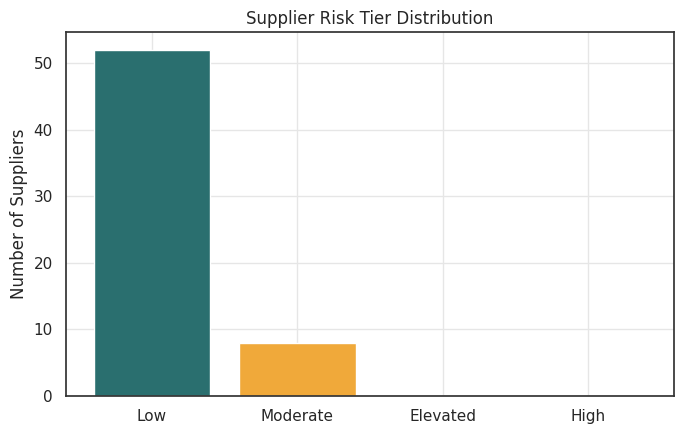

In [26]:
# ============================================================
# Supplier Risk Tier Distribution
# ============================================================

risk_tier_distribution = (
    supplier_risk_scores["RiskTier"]
    .value_counts(sort=False)
    .reindex(["Low", "Moderate", "Elevated", "High"])
    .fillna(0)
)

risk_colors = [
    COLOR_PALETTE[0],
    COLOR_PALETTE[2],
    COLOR_PALETTE[4],
    "#8B0000",
]

fig, ax = plt.subplots(figsize=(7, 4.5))

ax.bar(
    risk_tier_distribution.index,
    risk_tier_distribution.values,
    color=risk_colors
)

ax.set_title("Supplier Risk Tier Distribution")
ax.set_xlabel("")
ax.set_ylabel("Number of Suppliers")

plt.tight_layout()
plt.show()

## 6. Procurement Spend Forecasting

Forecast monthly procurement spend using trend and seasonal patterns, with a six-month holdout period to evaluate forecast accuracy before generating forward-looking estimates.

In [27]:
# ============================================================
# Procurement Spend Forecasting
# ============================================================

# ------------------------------------------------------------
# 1. Prepare Monthly Spend Series
# ------------------------------------------------------------

monthly_forecast_data = (
    fact_procurement_spend
    .merge(
        dim_date[["DateKey", "YearMonth"]],
        left_on="OrderDateKey",
        right_on="DateKey",
        how="left"
    )
    .groupby("YearMonth", as_index=False)["ActualSpend"]
    .sum()
    .sort_values("YearMonth")
    .reset_index(drop=True)
)

monthly_forecast_data["Date"] = pd.to_datetime(
    monthly_forecast_data["YearMonth"],
    errors="coerce"
)

monthly_forecast_data["Month"] = monthly_forecast_data["Date"].dt.month
monthly_forecast_data["t"] = np.arange(len(monthly_forecast_data))


# ------------------------------------------------------------
# 2. Forecasting Function
# ------------------------------------------------------------

def fit_seasonal_trend_forecast(train_df, forecast_horizon):
    """
    Fit a linear trend with multiplicative monthly seasonality
    and generate forward procurement spend forecasts.
    """

    model_data = train_df.copy()

    # Linear trend
    model = LinearRegression()
    model.fit(model_data[["t"]], model_data["ActualSpend"])

    model_data["Trend"] = model.predict(model_data[["t"]])

    # Avoid division by zero during seasonal decomposition
    model_data["Trend"] = model_data["Trend"].replace(0, np.nan)

    model_data["Detrended"] = (
        model_data["ActualSpend"] / model_data["Trend"]
    )

    # Monthly seasonal indices
    seasonal_index = (
        model_data
        .groupby("Month")["Detrended"]
        .mean()
    )

    seasonal_index = seasonal_index / seasonal_index.mean()

    last_t = model_data["t"].max()
    last_month = model_data["Month"].iloc[-1]

    forecast_rows = []

    for step in range(1, forecast_horizon + 1):

        future_t = last_t + step
        future_month = ((last_month - 1 + step) % 12) + 1

        trend_forecast = model.predict(
            pd.DataFrame({"t": [future_t]})
        )[0]

        seasonal_factor = seasonal_index.get(
            future_month,
            1.0
        )

        forecast_value = max(
            trend_forecast * seasonal_factor,
            0
        )

        forecast_rows.append(
            {
                "t": future_t,
                "Month": future_month,
                "Forecast": forecast_value,
            }
        )

    return pd.DataFrame(forecast_rows), model


# ------------------------------------------------------------
# 3. Six-Month Backtest
# ------------------------------------------------------------

HOLDOUT_MONTHS = 6

train_data = monthly_forecast_data.iloc[:-HOLDOUT_MONTHS].copy()
test_data = monthly_forecast_data.iloc[-HOLDOUT_MONTHS:].copy()

backtest_forecast, forecast_model = fit_seasonal_trend_forecast(
    train_data,
    HOLDOUT_MONTHS
)

backtest_forecast["YearMonth"] = test_data["YearMonth"].values
backtest_forecast["Actual"] = test_data["ActualSpend"].values

backtest_forecast["AbsolutePercentageError"] = (
    (
        backtest_forecast["Actual"]
        - backtest_forecast["Forecast"]
    ).abs()
    / backtest_forecast["Actual"].replace(0, np.nan)
)

mape = (
    backtest_forecast["AbsolutePercentageError"]
    .mean()
)

forecast_accuracy = max(0, 1 - mape)


# ------------------------------------------------------------
# 4. Backtest Results
# ------------------------------------------------------------

backtest_results = backtest_forecast[
    [
        "YearMonth",
        "Actual",
        "Forecast",
        "AbsolutePercentageError",
    ]
].copy()

backtest_results["APE_Pct"] = (
    backtest_results["AbsolutePercentageError"] * 100
)

display(
    backtest_results[
        ["YearMonth", "Actual", "Forecast", "APE_Pct"]
    ].round(2)
)

print(f"Backtest MAPE       : {mape * 100:.2f}%")
print(f"Forecast Accuracy   : {forecast_accuracy * 100:.2f}%")


# ------------------------------------------------------------
# 5. Six-Month Forward Forecast
# ------------------------------------------------------------

FORECAST_HORIZON = 6

future_forecast, _ = fit_seasonal_trend_forecast(
    monthly_forecast_data,
    FORECAST_HORIZON
)

last_date = monthly_forecast_data["Date"].max()

future_dates = pd.date_range(
    start=last_date + pd.DateOffset(months=1),
    periods=FORECAST_HORIZON,
    freq="MS"
)

future_forecast["YearMonth"] = (
    future_dates.strftime("%Y-%m")
)

# Management planning scenarios
future_forecast["LowerSpendScenario"] = (
    future_forecast["Forecast"] * 0.95
)

future_forecast["HigherSpendScenario"] = (
    future_forecast["Forecast"] * 1.08
)

forecast_output = future_forecast[
    [
        "YearMonth",
        "Forecast",
        "LowerSpendScenario",
        "HigherSpendScenario",
    ]
].copy()

display(forecast_output.round(0))

,YearMonth,Actual,Forecast,APE_Pct
0,2025-01,"56,443,517.41","63,316,386.37",12.18
1,2025-02,"52,816,028.91","59,482,721.31",12.62
2,2025-03,"52,097,104.00","57,648,473.91",10.66
3,2025-04,"54,800,798.52","54,310,254.31",0.90
4,2025-05,"55,492,564.15","55,475,716.21",0.03
5,2025-06,"42,482,927.02","46,126,833.05",8.58


Backtest MAPE       : 7.49%
Forecast Accuracy   : 92.51%


,YearMonth,Forecast,LowerSpendScenario,HigherSpendScenario
0,2025-07,"46,776,341.00","44,437,524.00","50,518,448.00"
1,2025-08,"53,295,100.00","50,630,345.00","57,558,708.00"
2,2025-09,"50,175,604.00","47,666,824.00","54,189,652.00"
3,2025-10,"55,051,268.00","52,298,705.00","59,455,370.00"
4,2025-11,"68,922,626.00","65,476,495.00","74,436,436.00"
5,2025-12,"71,625,495.00","68,044,220.00","77,355,534.00"


In [28]:
# ============================================================
# Export Spend Forecast Analytics for Power BI
# ============================================================

from pathlib import Path

OUTPUT_DIR = Path("/content/data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Historical monthly spend
# ------------------------------------------------------------

historical_powerbi = monthly_forecast_data[
    ["YearMonth", "ActualSpend"]
].copy()

historical_powerbi["PeriodType"] = "Actual"
historical_powerbi["Forecast"] = None
historical_powerbi["LowerSpendScenario"] = None
historical_powerbi["HigherSpendScenario"] = None

# ------------------------------------------------------------
# 2. Future six-month forecast
# ------------------------------------------------------------

forecast_powerbi = forecast_output.copy()

forecast_powerbi["PeriodType"] = "Forecast"
forecast_powerbi["ActualSpend"] = None

# ------------------------------------------------------------
# 3. Combine actual + forecast
# ------------------------------------------------------------

spend_forecast_powerbi = pd.concat(
    [
        historical_powerbi[
            [
                "YearMonth",
                "PeriodType",
                "ActualSpend",
                "Forecast",
                "LowerSpendScenario",
                "HigherSpendScenario",
            ]
        ],
        forecast_powerbi[
            [
                "YearMonth",
                "PeriodType",
                "ActualSpend",
                "Forecast",
                "LowerSpendScenario",
                "HigherSpendScenario",
            ]
        ],
    ],
    ignore_index=True,
)

# ------------------------------------------------------------
# 4. Add model evaluation metrics
# ------------------------------------------------------------

spend_forecast_powerbi["ForecastAccuracy"] = forecast_accuracy
spend_forecast_powerbi["MAPE"] = mape

# ------------------------------------------------------------
# 5. Save
# ------------------------------------------------------------

output_file = OUTPUT_DIR / "spend_forecast_powerbi.csv"

spend_forecast_powerbi.to_csv(
    output_file,
    index=False
)

print("Power BI forecast file created successfully.")
print(f"File: {output_file}")
print(f"Rows: {len(spend_forecast_powerbi):,}")

display(spend_forecast_powerbi.tail(12))

Power BI forecast file created successfully.
File: /content/data/processed/spend_forecast_powerbi.csv
Rows: 48


,YearMonth,PeriodType,ActualSpend,Forecast,LowerSpendScenario,HigherSpendScenario,ForecastAccuracy,MAPE
36,2025-01,Actual,"56,443,517.41",NaN,NaN,NaN,0.93,0.07
37,2025-02,Actual,"52,816,028.91",NaN,NaN,NaN,0.93,0.07
38,2025-03,Actual,"52,097,104.00",NaN,NaN,NaN,0.93,0.07
39,2025-04,Actual,"54,800,798.52",NaN,NaN,NaN,0.93,0.07
40,2025-05,Actual,"55,492,564.15",NaN,NaN,NaN,0.93,0.07
41,2025-06,Actual,"42,482,927.02",NaN,NaN,NaN,0.93,0.07
42,2025-07,Forecast,NaN,"46,776,340.84","44,437,523.80","50,518,448.11",0.93,0.07
43,2025-08,Forecast,NaN,"53,295,100.23","50,630,345.21","57,558,708.24",0.93,0.07
44,2025-09,Forecast,NaN,"50,175,603.82","47,666,823.63","54,189,652.12",0.93,0.07
45,2025-10,Forecast,NaN,"55,051,268.25","52,298,704.84","59,455,369.71",0.93,0.07


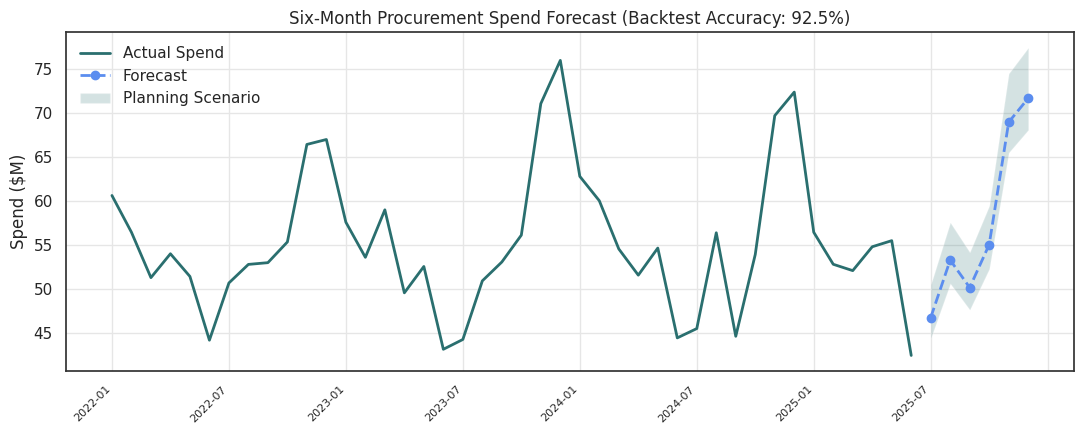

In [29]:
# ============================================================
# Procurement Spend Forecast
# ============================================================

fig, ax = plt.subplots(figsize=(11, 4.5))

# Historical Spend
ax.plot(
    monthly_forecast_data["YearMonth"],
    monthly_forecast_data["ActualSpend"] / 1_000_000,
    linewidth=2,
    label="Actual Spend"
)

# Forecast
ax.plot(
    future_forecast["YearMonth"],
    future_forecast["Forecast"] / 1_000_000,
    linestyle="--",
    marker="o",
    linewidth=2,
    label="Forecast"
)

# Scenario Band
ax.fill_between(
    future_forecast["YearMonth"],
    future_forecast["LowerSpendScenario"] / 1_000_000,
    future_forecast["HigherSpendScenario"] / 1_000_000,
    alpha=0.20,
    label="Planning Scenario"
)

ax.set_title(
    f"Six-Month Procurement Spend Forecast "
    f"(Backtest Accuracy: {forecast_accuracy * 100:.1f}%)"
)

ax.set_ylabel("Spend ($M)")
ax.set_xlabel("")

ax.xaxis.set_major_locator(mticker.MultipleLocator(6))

plt.xticks(
    rotation=45,
    ha="right",
    fontsize=8
)

ax.legend(frameon=False)

plt.tight_layout()
plt.show()

## 7. Supplier Segmentation (K-Means)

Segment suppliers using spend, delivery, quality, compliance, and concentration metrics to identify distinct supplier groups and support differentiated sourcing and supplier-management strategies.

In [30]:
# ============================================================
# Supplier Segmentation (K-Means)
# ============================================================

# ------------------------------------------------------------
# 1. Select Segmentation Features
# ------------------------------------------------------------

segmentation_features = [
    "TotalSpend",
    "OTIFRate",
    "DefectRate",
    "MaverickSpendPct",
    "SavingsRate",
]

supplier_segments = supplier_risk_scores[
    [
        "SupplierKey",
        "SupplierName",
        "SupplierTier",
        "SupplierRiskScore",
        *segmentation_features,
    ]
].copy()

X = supplier_segments[segmentation_features].fillna(0)


# ------------------------------------------------------------
# 2. Standardize Features
# ------------------------------------------------------------

segment_scaler = StandardScaler()

X_scaled = segment_scaler.fit_transform(X)


# ------------------------------------------------------------
# 3. Fit K-Means Model
# ------------------------------------------------------------

kmeans = KMeans(
    n_clusters=4,
    random_state=RANDOM_STATE,
    n_init=10
)

supplier_segments["Cluster"] = kmeans.fit_predict(X_scaled)


# ------------------------------------------------------------
# 4. Profile Cluster Characteristics
# ------------------------------------------------------------

cluster_profile = (
    supplier_segments
    .groupby("Cluster")[segmentation_features]
    .mean()
)

overall_profile = (
    supplier_segments[segmentation_features]
    .mean()
)


# ------------------------------------------------------------
# 5. Assign Business Segment Labels
# ------------------------------------------------------------

def assign_segment_label(row):
    """
    Translate statistical clusters into business-oriented
    supplier segments based on relative performance.
    """

    high_spend = (
        row["TotalSpend"]
        > overall_profile["TotalSpend"]
    )

    high_otif = (
        row["OTIFRate"]
        > overall_profile["OTIFRate"]
    )

    low_defect = (
        row["DefectRate"]
        < overall_profile["DefectRate"]
    )

    low_maverick = (
        row["MaverickSpendPct"]
        < overall_profile["MaverickSpendPct"]
    )

    if high_spend and high_otif and low_defect:
        return "Strategic Performers"

    if high_spend and not high_otif:
        return "High-Spend At-Risk"

    if (
        not high_spend
        and high_otif
        and low_defect
        and low_maverick
    ):
        return "Reliable Long-Tail"

    return "Development Required"


cluster_profile["Segment"] = (
    cluster_profile.apply(
        assign_segment_label,
        axis=1
    )
)

cluster_segment_map = (
    cluster_profile["Segment"]
    .to_dict()
)

supplier_segments["Segment"] = (
    supplier_segments["Cluster"]
    .map(cluster_segment_map)
)


# ------------------------------------------------------------
# 6. Segment Summary
# ------------------------------------------------------------

supplier_segment_summary = (
    supplier_segments
    .groupby("Segment")
    .agg(
        SupplierCount=("SupplierKey", "count"),
        TotalSpend=("TotalSpend", "sum"),
        AvgOTIF=("OTIFRate", "mean"),
        AvgDefectRate=("DefectRate", "mean"),
        AvgMaverickSpend=("MaverickSpendPct", "mean"),
        AvgRiskScore=("SupplierRiskScore", "mean"),
    )
    .reset_index()
    .sort_values(
        "TotalSpend",
        ascending=False
    )
)

display(
    supplier_segment_summary.round(3)
)

,Segment,SupplierCount,TotalSpend,AvgOTIF,AvgDefectRate,AvgMaverickSpend,AvgRiskScore
1,High-Spend At-Risk,33,"1,306,313,040.53",0.78,0.01,0.58,20.17
2,Reliable Long-Tail,18,"662,346,289.62",0.86,0.01,0.21,11.31
0,Development Required,9,"346,102,430.83",0.78,0.02,0.71,20.93


In [31]:
# ============================================================
# Export Supplier Segmentation for Power BI
# ============================================================

from pathlib import Path

supplier_segments_powerbi = supplier_segments[
    [
        "SupplierKey",
        "SupplierName",
        "SupplierTier",
        "SupplierRiskScore",
        "TotalSpend",
        "OTIFRate",
        "DefectRate",
        "MaverickSpendPct",
        "SavingsRate",
        "Cluster",
        "Segment",
    ]
].copy()

# Sort for easier review
supplier_segments_powerbi = (
    supplier_segments_powerbi
    .sort_values(
        ["Segment", "TotalSpend"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

OUTPUT_DIR = Path("/content/data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_file = OUTPUT_DIR / "supplier_segments_powerbi.csv"

supplier_segments_powerbi.to_csv(
    output_file,
    index=False
)

print("Power BI supplier segmentation file created successfully.")
print(f"File: {output_file}")
print(f"Suppliers: {len(supplier_segments_powerbi):,}")
print(f"Columns: {supplier_segments_powerbi.shape[1]}")

display(supplier_segments_powerbi.head(10))

Power BI supplier segmentation file created successfully.
File: /content/data/processed/supplier_segments_powerbi.csv
Suppliers: 60
Columns: 11


,SupplierKey,SupplierName,SupplierTier,SupplierRiskScore,TotalSpend,OTIFRate,DefectRate,MaverickSpendPct,SavingsRate,Cluster,Segment
0,39,Meridian Ltd.,Approved,14.71,"40,797,035.80",0.89,0.02,0.53,0.03,2,Development Required
1,28,Legacy Supply Co.,Transactional,19.50,"39,373,472.07",0.82,0.01,0.77,-0.01,2,Development Required
2,18,Apex Manufacturing,Transactional,22.14,"39,138,585.09",0.82,0.02,0.78,-0.01,2,Development Required
3,19,Precision Industries,Transactional,25.21,"38,927,028.64",0.83,0.01,0.75,-0.00,2,Development Required
4,47,Highland Solutions,Approved,19.18,"38,335,762.27",0.73,0.02,0.56,0.02,2,Development Required
5,42,Momentum Industries,Transactional,25.38,"37,925,483.85",0.66,0.02,0.81,-0.02,2,Development Required
6,26,Zenith Manufacturing,Transactional,22.90,"37,614,859.40",0.74,0.02,0.78,-0.01,2,Development Required
7,43,Horizon Ltd.,Approved,19.56,"37,375,457.72",0.73,0.02,0.57,0.02,2,Development Required
8,48,Fusion Group,Transactional,19.84,"36,614,745.99",0.81,0.01,0.81,-0.02,2,Development Required
9,14,Anchor Manufacturing,Transactional,35.20,"43,399,720.86",0.61,0.01,0.80,-0.02,3,High-Spend At-Risk


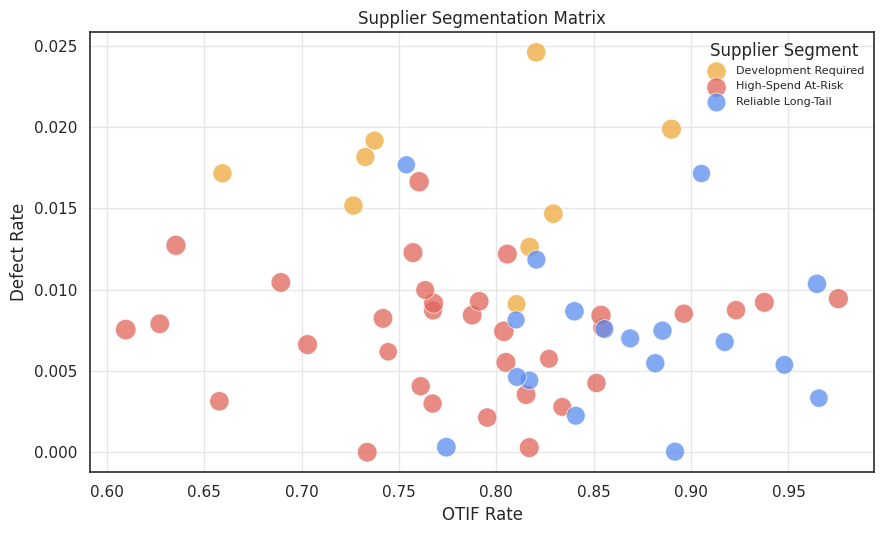

In [32]:
# ============================================================
# Supplier Segmentation Visualization
# ============================================================

segment_colors = {
    "Strategic Performers": COLOR_PALETTE[0],
    "High-Spend At-Risk": COLOR_PALETTE[4],
    "Reliable Long-Tail": COLOR_PALETTE[1],
    "Development Required": COLOR_PALETTE[2],
}

fig, ax = plt.subplots(figsize=(9, 5.5))

for segment, data in supplier_segments.groupby("Segment"):

    ax.scatter(
        data["OTIFRate"],
        data["DefectRate"],
        s=(data["TotalSpend"] / 200_000).clip(lower=30),
        alpha=0.75,
        edgecolor="white",
        linewidth=0.6,
        color=segment_colors.get(segment, "#808080"),
        label=segment,
    )

ax.set_title("Supplier Segmentation Matrix")
ax.set_xlabel("OTIF Rate")
ax.set_ylabel("Defect Rate")

ax.legend(
    title="Supplier Segment",
    fontsize=8,
    frameon=False,
    loc="upper right"
)

plt.tight_layout()
plt.show()

## 8. Business Insights & Recommendations

Key findings from the procurement analysis are summarized below.

| Business Insight | Estimated Impact / Management Action |
|---|---|
| Contract compliance remains below target, with material off-contract spend concentrated in selected categories | Prioritize high-spend categories for contract adoption and sourcing controls |
| A high-spend supplier segment shows weaker OTIF and elevated operational risk | Launch supplier development plans and renegotiate service-level commitments |
| Statistical anomaly detection identifies suppliers with unusual combinations of delivery, quality, and compliance risk | Escalate flagged suppliers for targeted risk review and contingency planning |
| Procurement spend shows predictable seasonal patterns | Use forecast outputs to improve budgeting, sourcing-event timing, and supplier negotiations |
| Supplier concentration varies significantly across categories | Reduce single-supplier dependency in categories with elevated concentration risk |
| High-performing suppliers combine stronger OTIF, lower defects, and higher compliance | Consider preferred-supplier status and greater strategic allocation |

Detailed category, supplier, and regional recommendations are documented in:

`docs/business_insights_and_recommendations.md`

### Related Project Deliverables

- `sql/` — data warehouse schema, ETL, KPI views, and analytical SQL
- `powerbi/` — semantic model, DAX measures, and executive dashboard specification
- `screenshots/` — dashboard previews and portfolio visuals
- `docs/` — data dictionary, methodology, recommendations, resume bullets, and interview talking points